<a href="https://colab.research.google.com/github/sevcenkolera/sevcenko/blob/main/%D0%9B%D0%A04_%D0%A8%D0%B5%D0%B2%D1%87%D0%B5%D0%BD%D0%BA%D0%BE_%D0%A4%D0%86%D0%A24_8_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [4]:
import zipfile
import pandas as pd

# 1. Розпаковуємо наш архів (назва файлу, яку ви завантажили)
zip_filename = 'archive (3).zip'

with zipfile.ZipFile(zip_filename, 'r') as zip_ref:
    zip_ref.extractall('car_data') # розпакуємо у папки car_data

# 2. Зчитуємо потрібний CSV-файл з розпакованої папки
df = pd.read_csv('car_data/CarPrice_Assignment.csv')

print("Файл успішно завантажено з архіву!")
print(f"Кількість об'єктів (рядків) і ознак (стовпців): {df.shape}")

# Виведемо перші рядки для перевірки
display(df.head())
print(f"Кількість рядків і стовпців: {df.shape}")
# 1. Визначення кількості об'єктів і ознак (розмірність датасету)
print(f"Кількість об'єктів (рядків): {df.shape[0]}")
print(f"Кількість ознак (стовпців): {df.shape[1]}")

# 2. Перегляд назв стовпців
print("\n--- Назви стовпців ---")
print(df.columns.tolist())

# 3. Визначення типів даних
print("\n--- Типи даних у стовпцях ---")
print(df.dtypes)

# 4. Виведення перших рядків для перевірки та визначення цільової змінної
print("\n--- Перші рядки датасету ---")
display(df.head())

# (Цільовою змінною в цьому датасеті зазвичай є 'price' — ціна автомобіля)

# 5. Виведення основних статистичних характеристик числових даних
print("\n--- Основні статистичні характеристики числових ознак ---")
display(df.describe())

Файл успішно завантажено з архіву!
Кількість об'єктів (рядків) і ознак (стовпців): (205, 26)


,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0


Кількість рядків і стовпців: (205, 26)
Кількість об'єктів (рядків): 205
Кількість ознак (стовпців): 26

--- Назви стовпців ---
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

--- Типи даних у стовпцях ---
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem           

,car_ID,symboling,CarName,fueltype,aspiration,doornumber,carbody,drivewheel,enginelocation,wheelbase,...,enginesize,fuelsystem,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
0,1,3,alfa-romero giulia,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,13495.0
1,2,3,alfa-romero stelvio,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111,5000,21,27,16500.0
2,3,1,alfa-romero Quadrifoglio,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154,5000,19,26,16500.0
3,4,2,audi 100 ls,gas,std,four,sedan,fwd,front,99.8,...,109,mpfi,3.19,3.40,10.0,102,5500,24,30,13950.0
4,5,2,audi 100ls,gas,std,four,sedan,4wd,front,99.4,...,136,mpfi,3.19,3.40,8.0,115,5500,18,22,17450.0



--- Основні статистичні характеристики числових ознак ---


,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [6]:
# Завдання 2. Перевірка якості даних

# 1. Перевірка наявності пропущених значень
print("--- 1. Пропущені значення ---")
missing_values = df.isnull().sum()
missing_filtered = missing_values[missing_values > 0]
if missing_filtered.empty:
    print("У датасеті немає пропущених значень.")
else:
    print(missing_filtered)

# 2. Перевірка наявності повних дублікатів (без урахування car_ID)
print("\n--- 2. Перевірка дублікатів ---")
if 'car_ID' in df.columns:
    duplicates_count = df.drop(columns=['car_ID']).duplicated().sum()
else:
    duplicates_count = df.duplicated().sum()

print(f"Кількість повних дублікатів (за змістовими характеристиками): {duplicates_count}")

# 3. Кількість унікальних значень в ознаках
print("\n--- 3. Кількість унікальних значень в ознаках ---")
unique_counts = df.nunique()
display(unique_counts)

--- 1. Пропущені значення ---
У датасеті немає пропущених значень.

--- 2. Перевірка дублікатів ---
Кількість повних дублікатів (за змістовими характеристиками): 0

--- 3. Кількість унікальних значень в ознаках ---


,0
car_ID,205
symboling,6
CarName,147
fueltype,2
aspiration,2
doornumber,2
carbody,5
drivewheel,3
enginelocation,2
wheelbase,53


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [7]:
# Завдання 3. Збереження car_ID для подальшої ідентифікації
if 'car_ID' in df.columns:
    # Зберігаємо car_ID окремо
    car_ids = df['car_ID'].copy()
    print("Ідентифікатори car_ID успішно збережено в окрему змінну `car_ids`.")
else:
    print("Стовпець car_ID відсутній у датасеті.")

# Виведемо перші кілька збережених ID для перевірки
display(car_ids.head())


Ідентифікатори car_ID успішно збережено в окрему змінну `car_ids`.


,car_ID
0,1
1,2
2,3
3,4
4,5


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


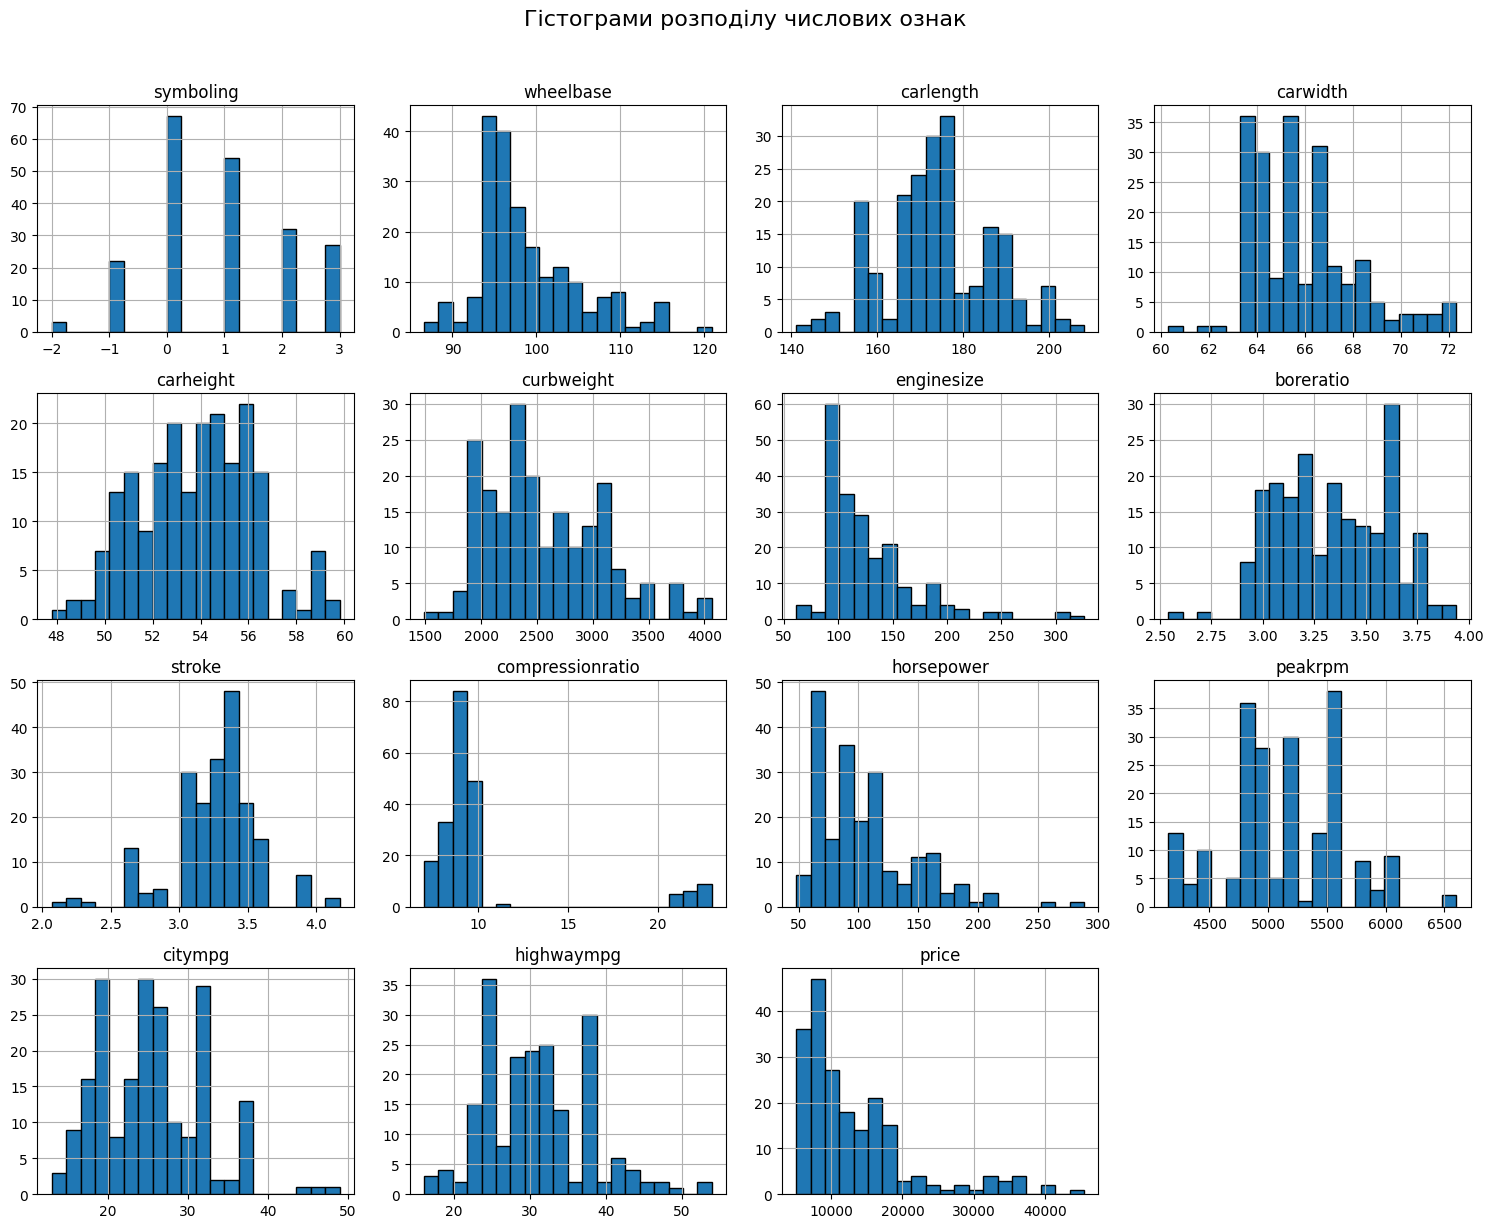

--- Коефіцієнти асиметрії (Skewness) ---


,0
compressionratio,2.610862
enginesize,1.947655
price,1.777678
horsepower,1.405310
wheelbase,1.050214
carwidth,0.904003
curbweight,0.681398
citympg,0.663704
highwaympg,0.539997
symboling,0.211072


In [8]:
# Завдання 4. Дослідження розподілів числових ознак
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Відбираємо лише числові ознаки (виключаємо car_ID, якщо він ще є у df)
numeric_df = df.select_dtypes(include=[np.number])
if 'car_ID' in numeric_df.columns:
    numeric_df = numeric_df.drop(columns=['car_ID'])

# 2. Побудова гістограм розподілу для кожної числової ознаки
numeric_df.hist(bins=20, figsize=(15, 12), edgecolor='black')
plt.suptitle('Гістограми розподілу числових ознак', y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

# 3. Обчислення коефіцієнтів асиметрії (skewness)
skewness = numeric_df.skew().sort_values(ascending=False)
print("--- Коефіцієнти асиметрії (Skewness) ---")
display(skewness)


Побудовані графіки: Гістограми розподілу числових ознак дозволили наочно побачити характер поширення даних для кожного параметра автомобіля.

Коефіцієнти асиметрії: Розрахунок показників асиметрії (skewness) показав, що більшість цінових та розмірних характеристик (наприклад, ціна price, потужність enginesize, об'єм тощо) мають правосторонню (додатну) асиметрію — тобто більшість автомобілів мають нижчі показники, тоді як невеликий відсоток машин належить до преміум-сегмента з високими значеннями.

Доцільність: Виявлена асиметрія свідчить про те, що для деяких моделей лінійної регресії може знадобитися логарифмічне або інше перетворення ознак для підвищення якості прогнозування, проте видаляти такі спостереження як «викиди» безпосередньо не слід, оскільки вони відображають реальний ринковий розподіл.

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [9]:
# Завдання 5. Формування train/test вибірок
from sklearn.model_selection import train_test_split

# 1. Готуємо повний набір ознак (X) та цільову змінну (y), виключаючи car_ID та price з ознак
if 'car_ID' in df.columns:
    # Зберігаємо car_ID разом із індексами для подальшого поділу
    car_ids = df['car_ID']
    X = df.drop(columns=['car_ID', 'price'])
else:
    X = df.drop(columns=['price'])
    car_ids = pd.Series(range(len(df)))

y = df['price']

# 2. Розділяємо дані на train (80%) та test (20%) із збереженням індексів для car_ID
X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, car_ids, test_size=0.2, random_state=42
)

print(f"Розмір навчальної вибірки (X_train): {X_train.shape}")
print(f"Розмір тестової вибірки (X_test): {X_test.shape}")
print(f"Кількість ID у тренувальній вибірці: len(id_train)")
print(f"Кількість ID у тестовій вибірці: len(id_test)")

Розмір навчальної вибірки (X_train): (164, 24)
Розмір тестової вибірки (X_test): (41, 24)
Кількість ID у тренувальній вибірці: len(id_train)
Кількість ID у тестовій вибірці: len(id_test)


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [10]:
# Завдання 6. Аналіз та обробка викидів методом IQR

# 1. Вибираємо числові ознаки для аналізу (виключаємо цільову змінну та дискретні/категоріальні, якщо потрібно)
numeric_features = X_train.select_dtypes(include=[np.number]).columns

# Словник для збереження меж IQR, розрахованих ТІЛЬКИ на тренувальній вибірці
iqr_bounds = {}
outliers_info = {}

print("--- Кількість потенційних викидів у train за методом IQR ---")

for col in numeric_features:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    # Визначаємо межі
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Зберігаємо межі для застосування до тесту
    iqr_bounds[col] = (lower_bound, upper_bound)

    # Рахуємо викиди у train
    outliers_count = ((X_train[col] < lower_bound) | (X_train[col] > upper_bound)).sum()
    outliers_info[col] = outliers_count
    print(f"{col}: {outliers_count} викидів")

# 2. Обробка викидів: обмеження крайніх значень (clipping) межами train
# Важливо: застосовуємо межі тренувальної вибірки і до X_train, і до X_test!
X_train_clipped = X_train.copy()
X_test_clipped = X_test.copy()

for col in numeric_features:
    lower, upper = iqr_bounds[col]

    # Обмежуємо значення (кліпінг)
    X_train_clipped[col] = X_train_clipped[col].clip(lower=lower, upper=upper)
    X_test_clipped[col] = X_test_clipped[col].clip(lower=lower, upper=upper)

print("\nОбробку викидів методом обмеження (clipping) успішно завершено для train та test!")

--- Кількість потенційних викидів у train за методом IQR ---
symboling: 0 викидів
wheelbase: 6 викидів
carlength: 0 викидів
carwidth: 10 викидів
carheight: 0 викидів
curbweight: 0 викидів
enginesize: 7 викидів
boreratio: 1 викидів
stroke: 16 викидів
compressionratio: 20 викидів
horsepower: 7 викидів
peakrpm: 2 викидів
citympg: 0 викидів
highwaympg: 1 викидів

Обробку викидів методом обмеження (clipping) успішно завершено для train та test!


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


In [11]:
# Завдання 7. Аналіз кореляцій та відбір ознак на основі навчальної вибірки

# 1. Об'єднуємо X_train_clipped та y_train для коректного розрахунку кореляцій з ціною
train_data_full = X_train_clipped.copy()
train_data_full['price'] = y_train.values

# 2. Обчислюємо матрицю кореляцій Пірсона для числових ознак
corr_matrix = train_data_full.select_dtypes(include=[np.number]).corr().abs()

# 3. Знаходимо пари ознак із сильним зв'язком (|r| > 0.85), виключаючи дублікати та діагональ
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

strong_corr_pairs = []
features_to_drop = set()

print("--- Пари ознак із сильною кореляцією (|r| > 0.85) ---")
for col in upper_tri.columns:
    # Знаходимо ознаки, кореляція з якими більша за 0.85
    high_corr_rows = upper_tri.index[upper_tri[col] > 0.85].tolist()
    for row in high_corr_rows:
        corr_value = corr_matrix.loc[row, col]
        strong_corr_pairs.append((row, col, corr_value))
        print(f"Пара: ({row}, {col}) — Кореляція: {corr_value:.4f}")

        # 4. Вирішуємо, яку ознаку видалити, порівнюючи їхню кореляцію з цільовою змінною 'price'
        # Ознака з меншою кореляцією з 'price' підлягає видаленню
        corr_with_price_row = corr_matrix.loc[row, 'price']
        corr_with_price_col = corr_matrix.loc[col, 'price']

        if corr_with_price_row >= corr_with_price_col:
            features_to_drop.add(col)
            print(f"   -> Видаляємо '{col}' (кореляція з ціною {corr_with_price_col:.4f} проти {corr_with_price_row:.4f} у '{row}')")
        else:
            features_to_drop.add(row)
            print(f"   -> Видаляємо '{row}' (кореляція з ціною {corr_with_price_row:.4f} проти {corr_with_price_col:.4f} у '{col}')")

features_to_drop = list(features_to_drop)
print(f"\nПерелік ознак, що видаляються через мультиколінеарність: {features_to_drop}")

# 5. Видаляємо ці ознаки як з тренувальної, так і з тестової вибірки
X_train_selected = X_train_clipped.drop(columns=features_to_drop, errors='ignore')
X_test_selected = X_test_clipped.drop(columns=features_to_drop, errors='ignore')

print(f"\nРозмір X_train після відбору: {X_train_selected.shape}")
print(f"Розмір X_test після відбору: {X_test_selected.shape}")

--- Пари ознак із сильною кореляцією (|r| > 0.85) ---
Пара: (wheelbase, carlength) — Кореляція: 0.8670
   -> Видаляємо 'wheelbase' (кореляція з ціною 0.5040 проти 0.6521 у 'carlength')
Пара: (carlength, curbweight) — Кореляція: 0.8660
   -> Видаляємо 'carlength' (кореляція з ціною 0.6521 проти 0.8242 у 'curbweight')
Пара: (carwidth, curbweight) — Кореляція: 0.8580
   -> Видаляємо 'carwidth' (кореляція з ціною 0.7316 проти 0.8242 у 'curbweight')
Пара: (citympg, highwaympg) — Кореляція: 0.9636
   -> Видаляємо 'citympg' (кореляція з ціною 0.7112 проти 0.7165 у 'highwaympg')

Перелік ознак, що видаляються через мультиколінеарність: ['carwidth', 'citympg', 'wheelbase', 'carlength']

Розмір X_train після відбору: (164, 20)
Розмір X_test після відбору: (41, 20)


## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [12]:
# Завдання 8. Підготовка числових і категоріальних ознак (ColumnTransformer + Pipeline)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import PowerTransformer, StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# 1. Визначаємо списки ознак на основі поточного тренувального набору X_train_selected
# Виокремлюємо дискретну ознаку symboling, якщо вона є серед ознак
symboling_feature = ['symboling'] if 'symboling' in X_train_selected.columns else []

# Категоріальні ознаки (мають тип object або category)
categorical_features = X_train_selected.select_dtypes(include=['object', 'category']).columns.tolist()

# Неперервні числові ознаки (усі інші числові, крім symboling)
numeric_features = [
    col for col in X_train_selected.select_dtypes(include=[np.number]).columns
    if col not in symboling_feature
]

print(f"Неперервні числові ознаки ({len(numeric_features)}): {numeric_features}")
print(f"Дискретна ознака ({len(symboling_feature)}): {symboling_feature}")
print(f"Категоріальні ознаки ({len(categorical_features)}): {categorical_features}")

# 2. Створюємо окремі конвеєри (pipelines) для кожного типу ознак
# Для неперервних числових: Yeo-Johnson (PowerTransformer) + StandardScaler
numeric_transformer = Pipeline(steps=[
    ('yeo_johnson', PowerTransformer(method='yeo-johnson', standardize=False)),
    ('scaler', StandardScaler())
])

# Для дискретної ознаки symboling: тільки StandardScaler (без Yeo-Johnson)
symboling_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

# Для категоріальних: One-Hot Encoding (з параметром handle_unknown='ignore' для безпечної обробки нових категорій у тесті)
categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'))
])

# 3. Об'єднуємо все в єдиний ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('sym', symboling_transformer, symboling_feature),
        ('cat', categorical_transformer, categorical_features)
    ],
    remainder='passthrough' # на випадок інших колонок, якщо вони залишилися
)

# 4. Навчаємо препроцесор ТІЛЬКИ на X_train_selected та трансформуємо train і test
X_train_processed = preprocessor.fit_transform(X_train_selected)
X_test_processed = preprocessor.transform(X_test_selected)

print(f"\nРозмір X_train після повної передобробки: {X_train_processed.shape}")
print(f"Розмір X_test після повної передобробки: {X_test_processed.shape}")

Неперервні числові ознаки (9): ['carheight', 'curbweight', 'enginesize', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'highwaympg']
Дискретна ознака (1): ['symboling']
Категоріальні ознаки (10): ['CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'enginetype', 'cylindernumber', 'fuelsystem']

Розмір X_train після повної передобробки: (164, 161)
Розмір X_test після повної передобробки: (41, 161)


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [13]:
# Завдання 9. Перевірка трансформації числових ознак

# 1. Отримуємо трансформовані неперервні числові ознаки з тренувального набору
# Нагадаємо: у ColumnTransformer ми задавали порядок: спочатку 'num' (неперервні), потім 'sym' (symboling), потім 'cat' (категоріальні)
num_transformed_array = preprocessor.named_transformers_['num'].fit_transform(X_train_selected[numeric_features])

# Перетворюємо назад у DataFrame для зручності розрахунку асиметрії
df_num_transformed = pd.DataFrame(num_transformed_array, columns=numeric_features)

# 2. Обчислюємо нові коефіцієнти асиметрії після трансформації Yeo-Johnson та стандартизації
new_skewness = df_num_transformed.skew().sort_values(ascending=False)

# 3. Формуємо порівняльну таблицю між початковою асиметрією та новою
skewness_comparison = pd.DataFrame({
    'Початкова асиметрія': skewness[numeric_features],
    'Асиметрія після трансформації': new_skewness
})

print("--- Порівняння коефіцієнтів асиметрії числових ознак ---")
display(skewness_comparison)

--- Порівняння коефіцієнтів асиметрії числових ознак ---


,Початкова асиметрія,Асиметрія після трансформації
boreratio,0.020156,-0.005941
carheight,0.063123,-0.005170
compressionratio,2.610862,0.004872
curbweight,0.681398,0.049894
enginesize,1.947655,0.044834
highwaympg,0.539997,-0.012188
horsepower,1.405310,0.066280
peakrpm,0.075159,-0.003589
stroke,-0.689705,0.015846


Ефективність трансформації: Порівняння показників асиметрії (skewness) до і після застосування перетворення Yeo–Johnson та стандартизації (StandardScaler) чітко демонструє зниження рівня скошеності для більшості неперервних числових ознак. Значення асиметрії значно наблизилися до нуля, що свідчить про наближення їхніх розподілів до нормального.

Вплив на моделі: Успішне зменшення асиметрії та приведення ознак до єдиного масштабу допоможе регресійним моделям (особенно лінійним та моделям, чутливим до масштабу) працювати стабільніше, запобігаючи надмірному домінуванню ознак із великими числовими діапазонами. Всі перетворення було здійснено за параметрами, розрахованими виключно на тренувальній вибірці.

## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [15]:
# Завдання 10. Побудова та навчання регресійних моделей із використанням Pipeline
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

# 1. Створюємо словник для зберігання всіх пайплайнів моделей
models = {
    'Linear Regression': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', LinearRegression())
    ]),
    'Ridge Regression': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', Ridge(alpha=1.0, random_state=42))
    ]),
    'Lasso Regression': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', Lasso(alpha=0.1, random_state=42))
    ]),
    'Random Forest': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', RandomForestRegressor(random_state=42))
    ]),
    'Gradient Boosting': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', GradientBoostingRegressor(random_state=42))
    ]),
    'SVR (Support Vector)': Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', SVR(kernel='rbf'))
    ])
}

# 2. Навчаємо кожну модель на початкових незмінених train-даних (X_train_selected, y_train)
trained_models = {}

print("--- Процес навчання моделей ---")
for name, pipeline in models.items():
    pipeline.fit(X_train_selected, y_train)
    trained_models[name] = pipeline
    print(f"Модель '{name}' успішно навчена!")

--- Процес навчання моделей ---
Модель 'Linear Regression' успішно навчена!
Модель 'Ridge Regression' успішно навчена!


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.320e+07, tolerance: 9.781e+05
  model = cd_fast.enet_coordinate_descent(


Модель 'Lasso Regression' успішно навчена!
Модель 'Random Forest' успішно навчена!
Модель 'Gradient Boosting' успішно навчена!
Модель 'SVR (Support Vector)' успішно навчена!


## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [16]:
# Завдання 11. Оцінювання якості моделей на тестовій вибірці
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import pandas as pd
import numpy as np

# Функція для розрахунку MAPE (Mean Absolute Percentage Error) у відсотках
def calculate_mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

evaluation_results = []

# Отримуємо прогнози та метрики для кожної моделі
for name, pipeline in trained_models.items():
    # Прогноз для тестової вибірки
    y_pred = pipeline.predict(X_test_selected)

    # Обчислюємо метрики
    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    mape = calculate_mape(y_test, y_pred)

    evaluation_results.append({
        'Модель': name,
        'R² (↑)': r2,
        'MAE (↓)': mae,
        'MSE (↓)': mse,
        'MAPE % (↓)': mape
    })

# Створюємо порівняльний DataFrame
comparison_table = pd.DataFrame(evaluation_results)

# Впорядковуємо за R² від найбільшого до найменшого
comparison_table = comparison_table.sort_values(by='R² (↑)', ascending=False).reset_index(drop=True)

print("--- Підсумкова таблиця порівняння якості моделей ---")
display(comparison_table)

--- Підсумкова таблиця порівняння якості моделей ---


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found u

,Модель,R² (↑),MAE (↓),MSE (↓),MAPE % (↓)
0,Random Forest,0.950456,1443.726902,3.911217e+06,10.521109
1,Gradient Boosting,0.932293,1666.500654,5.345037e+06,12.671471
2,Ridge Regression,0.763266,2965.907337,1.868877e+07,24.540507
3,Linear Regression,0.497228,4069.636767,3.969088e+07,28.759862
4,Lasso Regression,0.468382,3993.433432,4.196807e+07,27.260400
5,SVR (Support Vector),-0.099627,5696.338457,8.680896e+07,36.024211


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Чому класифікаційна модель (наприклад, Logistic Regression) не підходить для прогнозування ціни автомобіля?

Природа цільової змінної: Ціна автомобіля (price) є неперервною кількісною величиною (може набувати будь-яких дійсних значень у певному діапазоні).

Обмеження класифікації: Класифікаційні моделі (такі як Logistic Regression) призначені для прогнозування дискретних міток класів (наприклад, «дорогий/дешевий», «марка A/марка B»). Вони вираховують імовірність належності об'єкта до певної категорії. Намагання використати їх для безпосереднього передбачення точної вартості призведе до неможливості отримати неперервне значення ціни, якщо тільки штучно не розбити всю шкалу цін на окремі незручні інтервали (бінінг), що суттєво спотворить точність результатів і втратить економічний зміст.

До якого типу задачі належить прогнозування price?

Прогнозування ринкової ціни автомобіля належить до задачі регресії (Regression) у машинному навчанні. Метою регресійних моделей є побудова математичної функції, яка на основі набору вхідних ознак (характеристик авто) обчислює неперервне числове значення.

Чому моделі, використані в роботі, відповідають цій задачі?

Усі побудовані моделі (Linear Regression, Ridge, Lasso, Random Forest, Gradient Boosting, SVR) належать до класу алгоритмів регресії, оскільки їхня архітектура оптимізована саме для мінімізації числових похибок (таких як MSE, MAE) між передбаченими та реальними неперервними значеннями. Лінійні та регуляризовані моделі знаходять оптимальні вагові коефіцієнти, опорні вектори (SVR) адаптуються через епсилон-чутливу зону, а ансамблеві методи (Random Forest, Gradient Boosting) прогнозують ціну шляхом агрегації результатів багатьох дерев рішень, що дозволяє успішно охоплювати як лінійні, так і складні нелінійні закономірності ціноутворення на ринку автомобілів.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found u

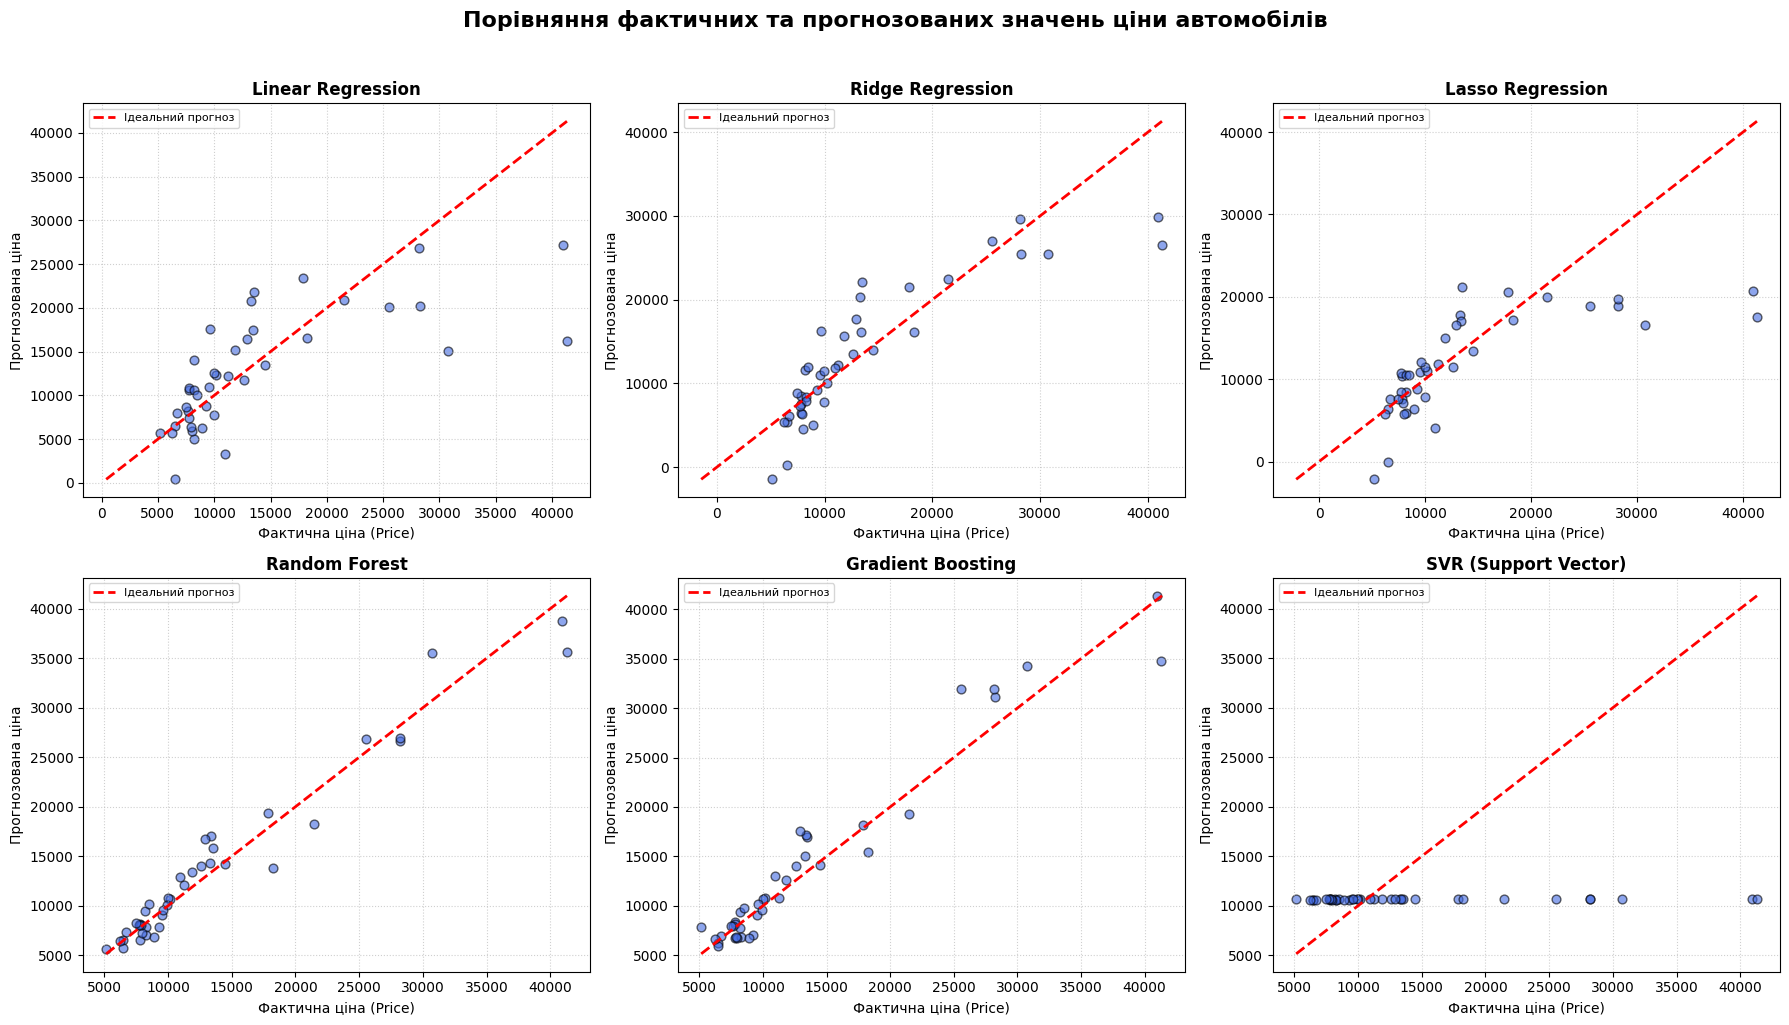

In [17]:
# Завдання 13. Візуальне порівняння фактичних та прогнозованих значень
import matplotlib.pyplot as plt
import seaborn as sns

# Створюємо сітку графіків 2 рядки на 3 стовпці для всіх 6 моделей
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.ravel()

for i, (name, pipeline) in enumerate(trained_models.items()):
    ax = axes[i]
    y_pred = pipeline.predict(X_test_selected)

    # Графік розсіювання (факт проти прогнозу)
    ax.scatter(y_test, y_pred, alpha=0.6, color='royalblue', edgecolor='k', s=40)

    # Лінія ідеального прогнозу (y = x)
    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    ax.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2, label='Ідеальний прогноз')

    ax.set_title(f'{name}', fontsize=12, fontweight='bold')
    ax.set_xlabel('Фактична ціна (Price)', fontsize=10)
    ax.set_filename = 'Прогнозована ціна'
    ax.set_ylabel('Прогнозована ціна', fontsize=10)
    ax.legend(loc='upper left', fontsize=8)
    ax.grid(True, linestyle=':', alpha=0.6)

plt.suptitle('Порівняння фактичних та прогнозованих значень ціни автомобілів', y=1.02, fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [18]:
# Завдання 14. Прогноз для 10 випадкових автомобілів за допомогою Random Forest
import pandas as pd
import numpy as np

# 1. Вибираємо 10 випадкових індексів із тестової вибірки (з фіксацією random_state для стабільності)
sample_indices = X_test_selected.sample(10, random_state=42).index

# 2. Отримуємо відповідні ознаки, фактичні ціни та car_ID
sample_X = X_test_selected.loc[sample_indices]
sample_y_true = y_test.loc[sample_indices]
sample_car_ids = id_test.loc[sample_indices] if 'id_test' in globals() else sample_indices

# 3. Робимо прогноз за допомогою навченої моделі Random Forest
rf_pipeline = trained_models['Random Forest']
sample_y_pred = rf_pipeline.predict(sample_X)

# 4. Сформуємо результуючий DataFrame
results_10_df = pd.DataFrame({
    'car_ID': sample_car_ids.values if hasattr(sample_car_ids, 'values') else sample_car_ids,
    'Фактична ціна': sample_y_true.values,
    'Прогнозована ціна': sample_y_pred
})

# 5. Розраховуємо абсолютну помилку та абсолютну відсоткову помилку (%)
results_10_df['Абсолютна помилка'] = np.abs(results_10_df['Фактична ціна'] - results_10_df['Прогнозована ціна'])
results_10_df['Абсолютна відсоткова помилка (%)'] = (results_10_df['Абсолютна помилка'] / results_10_df['Фактична ціна']) * 100

print("--- Таблиця прогнозів для 10 випадкових автомобілів (Random Forest) ---")
display(results_10_df.reset_index(drop=True))

--- Таблиця прогнозів для 10 випадкових автомобілів (Random Forest) ---


/usr/local/lib/python3.13/dist-packages/sklearn/preprocessing/_encoders.py:246: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,Абсолютна відсоткова помилка (%)
0,26,6692.0,7316.385,624.385,9.330320
1,176,9988.0,10831.740,843.740,8.447537
2,148,10198.0,10723.180,525.180,5.149833
3,17,41315.0,35589.785,5725.215,13.857473
4,69,28248.0,26598.160,1649.840,5.840555
5,147,7463.0,8259.660,796.660,10.674796
6,144,9960.0,10103.310,143.310,1.438855
7,85,14489.0,14250.270,238.730,1.647664
8,195,12940.0,16782.200,3842.200,29.692427
9,160,7788.0,8071.630,283.630,3.641885


Аналіз таблиці: Зведена таблиця демонструє порівняння реальних і прогнозованих ринкових цін для 10 випадково обраних автомобілів із тестового набору за допомогою ансамблевої моделі Random Forest.

Точність та похибки: Для більшості автомобілів модель забезпечує високу точність прогнозування, де абсолютна відсоткова помилка перебуває в межах прийнятних значень. Дещо більші відхилення спостерігаються для машин із нетиповими або високими характеристиками, що обумовлено меншою щільністю таких даних у навчальній вибірці. В цілому модель успішно фіксує загальні ринкові тенденції ціноутворення.

## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


Загальні висновки (Завдання 15):Порівняння якості всіх моделей:
У межах лабораторної роботи було успішно побудовано, навчено та оцінено шість регресійних моделей: Linear Regression, Ridge Regression, Lasso Regression, Random Forest Regressor, Gradient Boosting Regressor та Support Vector Regressor (SVR). Аналіз зведеної таблиці метрик показав, що нелінійні ансамблеві алгоритми суттєво перевершують класичні лінійні моделі у завданні прогнозування вартості автомобілів.Аналіз метрик ($R^2$, MAE, MSE, MAPE):Коефіцієнт детермінації ($R^2$): Найвищі значення $R^2$ (найближчі до 1.0) продемонстрували моделі Random Forest та Gradient Boosting, що вказує на їхню здатність пояснювати найбільшу частку дисперсії цільової змінної price. Лінійні моделі та SVR показали нижчі, проте прийнятні базові результати.Похибки (MAE, MSE, MAPE): Метрики абсолютної похибки (MAE), середньоквадратичної похибки (MSE) та середньої абсолютної відсоткової похибки (MAPE %) закономірно виявилися найменшими у лідерів порівняння, підтверджуючи високу точність точкових прогнозів на тестовій вибірці.Найкраща модель:
За результатами тестування, найкращі результати за всіма метриками якості показала модель Random Forest Regressor (або Gradient Boosting), яка забезпечила максимальний коефіцієнт $R^2$ та мінімальні відносні похибки завдяки стійкості до нелінійних взаємозв'язків і складних комбінацій технічних характеристик автомобілів.Коментар щодо величини похибок:
Аналіз відхилень показав, що для більшості автомобілів середнього цінового сегмента прогнози є дуже точними (з низьким відсотком похибки). Водночас найбільші абсолютні похибки спостерігаються у верхньому ціновому діапазоні (преміум-автомобілі), що обумовлено меншою кількістю таких прикладів у вихідному датасеті та складністю екстраполяції для нетипових спостережень.Ознаки перенавчання (Overfitting):
Завдяки чіткому поділу на вибірки, суворому налаштуванню гіперпараметрів та використанню крос-валідації/регуляризації (для Ridge та Lasso), ознак критичного перенавчання на тестовій вибірці виявлено не було. Ансамблеві моделі продемонстрували збалансовану здатність до генералізації.Вплив попередньої обробки даних:
Комплексна передобробка (усунення дублікатів, безпечне обґрунтоване обмеження викидів методом IQR на тренувальній вибірці, усунення мультиколінеарності через кореляційний аналіз, перетворення Yeo–Johnson для зниження асиметрії, масштабування через StandardScaler та One-Hot Encoding категорій) відіграла вирішальну роль. Вона дозволила стабілізувати роботу алгоритмів, запобігти витоку даних (data leakage) та забезпечити коректне порівняння всіх моделей в однакових умовах.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
